**AICE Associate <font color=red>사례실습</font> — 통신사 고객 이탈 예측 ② 머신러닝 · 딥러닝**

### <span style="color:darkgreen">**이탈(Churn) 고객을 예측하는 머신러닝 · 딥러닝 모델 개발**</span>
---

- 도메인 : 통신
- 목  표 : 14번에서 전처리한 데이터로 여러 모델을 학습·비교하고, 이탈 고객을 가장 잘 찾아내는 모델을 고릅니다.<br>
C사 마케팅팀은 이탈할 고객에게 미리 혜택을 제공하려고 합니다. **실제 이탈 고객을 놓치지 않는 것(Recall)** 이 중요하지만,
너무 많은 고객에게 혜택을 주면 비용이 커지므로 **F1 score**를 함께 봅니다.

---

#### **<span style="color:red">[유의사항]</span>**
- 14번 노트북을 먼저 실행해 `churn_preprocessed.csv`를 만들어 두세요. (없으면 2번의 준비 셀이 자동으로 만들어 줍니다)
- 문항에 변수명이 제시된 경우 반드시 해당 변수명을 사용하세요.

<br>

## <font color=blue>**<데이터 준비>**</font>

### **1. 아래 라이브러리를 불러오세요.**
---
- sklearn.model_selection 에서 train_test_split, GridSearchCV
- sklearn.preprocessing 에서 StandardScaler
- sklearn.metrics 에서 accuracy_score, recall_score, f1_score, confusion_matrix, classification_report
---

In [1]:
# [1번 정답]
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, recall_score, f1_score, confusion_matrix, classification_report

> **다음 문항을 풀기 전에 <span style="color:red">아래 코드를 실행하세요.</span>**

In [2]:
import platform
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.font_manager as fm
import warnings
warnings.filterwarnings('ignore')

# OS에 따라서 한글 폰트 로드
os_name = platform.system()

if os_name == 'Linux':
    font_names = [f.name for f in fm.fontManager.ttflist]
    for cand in ['NanumGothicCoding', 'NanumGothic', 'Noto Sans CJK KR', 'Noto Sans CJK JP']:
        if cand in font_names:
            plt.rc('font', family=cand)
            break
    print("(리눅스) 한글폰트 로드 완료")
elif os_name == 'Windows':
    font_path = 'C:\\Windows\\Fonts\\malgun.ttf'
    font = fm.FontProperties(fname=font_path).get_name()
    mpl.rc('font', family=font)
    print("(윈도우) 한글폰트 로드 완료")
elif os_name == 'Darwin':
    plt.rc('font', family='AppleGothic')
    print("(맥) 한글폰트 로드 완료")
else:
    print(f"알 수 없는 OS입니다: {os_name}")

# 마이너스 기호 깨짐 방지
mpl.rcParams['axes.unicode_minus'] = False

(리눅스) 한글폰트 로드 완료


In [3]:
# [준비] churn_preprocessed.csv 가 없으면 14번 전처리를 자동으로 수행해 파일을 만듭니다. (그대로 실행)
import os
if not os.path.exists('churn_preprocessed.csv'):
    cust = pd.read_csv('cust_info.csv').drop_duplicates()
    service = pd.read_csv('service_info.csv')
    _df = pd.merge(cust, service, on='customerID', how='inner')
    _df['TotalCharges'] = pd.to_numeric(_df['TotalCharges'], errors='coerce').fillna(0)
    _df['MonthlyCharges'] = _df['MonthlyCharges'].fillna(_df['MonthlyCharges'].median())
    for c in ['Dependents', 'PaymentMethod']:
        _df[c] = _df[c].fillna(_df[c].mode()[0])
    _df = _df.drop('customerID', axis=1)
    _df['Churn'] = _df['Churn'].map({'Yes': 1, 'No': 0})
    _df = pd.get_dummies(_df, columns=_df.select_dtypes(include='object').columns.tolist(), dtype=int)
    _df.to_csv('churn_preprocessed.csv', index=False)
    print('churn_preprocessed.csv 생성 완료')
else:
    print('churn_preprocessed.csv 가 이미 있습니다')

churn_preprocessed.csv 가 이미 있습니다


<br>

### **2. churn_preprocessed.csv를 읽어 df에 저장하고, 이탈(Churn=1) 고객의 비율을 소수점 셋째 자리까지 반올림해 '답안2'에 저장하세요.**
---

In [4]:
# [2번 정답]
df = pd.read_csv('churn_preprocessed.csv')
print(df.shape)
print(df['Churn'].mean())
답안2 = 0.352

(7043, 46)
0.35198069004685506


<br>

### **3. Churn을 레이블 y로, 나머지를 피처 X로 하여 훈련/검증 데이터셋으로 분리하세요.**
---
- 훈련:검증 = 80:20, 난수 시드 42, 이탈 비율 유지(stratify)
- 변수명 : X_train, X_valid, y_train, y_valid
---

In [5]:
# [3번 정답]
X = df.drop('Churn', axis=1)
y = df['Churn']
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_valid.shape)

(5634, 45) (1409, 45)


<br>

### **4. StandardScaler로 스케일링하는 코드의 오류를 정정하세요.**
---
- 스케일러는 scaler 변수, 스케일 결과는 X_train, X_valid에 그대로 저장
- 스케일링된 **훈련**데이터의 최댓값을 반올림하여 '답안4'에 저장하세요.
---

In [6]:
# [4번 정답]
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_valid = scaler.transform(X_valid)
print(round(np.max(X_train)))

답안4 = 3

3


<br>

## <font color=blue>**<머신러닝 모델링>**</font>

### **5. 로지스틱 회귀 모델을 만들고 학습하세요.**
---
- sklearn.linear_model의 LogisticRegression 사용, max_iter=1000, 변수명 lg
- 검증데이터의 예측값을 y_pred_lg에 저장하고 accuracy와 f1 score를 출력하세요.
---

In [7]:
# [5번 정답]
from sklearn.linear_model import LogisticRegression

lg = LogisticRegression(max_iter=1000)
lg.fit(X_train, y_train)
y_pred_lg = lg.predict(X_valid)
print('accuracy:', accuracy_score(y_valid, y_pred_lg))
print('f1      :', f1_score(y_valid, y_pred_lg))

accuracy: 0.7572746628814763
f1      : 0.6647058823529411


<br>

### **6. DecisionTree와 RandomForest 모델을 만드세요.**

- **[6-1] DecisionTree 모델 (변수명 dt)**
  - max_depth=5, min_samples_split=10, random_state=42
  - 훈련데이터로 학습하고, 검증 예측값을 y_pred_dt에 저장하세요.
---

In [8]:
# [6-1번 정답]
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(max_depth=5, min_samples_split=10, random_state=42)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_valid)

- **[6-2] RandomForest 모델을 GridSearchCV로 탐색하세요. (변수명 gs_rf)**
  - n_estimators 후보 : [100, 200]
  - max_depth 후보 : [5, 10]
  - min_samples_split 후보 : [2, 10]
  - cv=3, **scoring='f1'**, n_jobs=-1, RandomForest의 random_state=42
  - 최적 모델의 검증 예측값을 y_pred_rf에 저장하세요.
  - 최적 하이퍼파라미터의 max_depth 값을 '답안6'에 저장하세요.
---

In [9]:
# [6-2번 정답]
from sklearn.ensemble import RandomForestClassifier

param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [5, 10],
    'min_samples_split': [2, 10]
}
gs_rf = GridSearchCV(RandomForestClassifier(random_state=42), param_grid=param_grid, cv=3, scoring='f1', n_jobs=-1)
gs_rf.fit(X_train, y_train)
print(gs_rf.best_params_)

y_pred_rf = gs_rf.best_estimator_.predict(X_valid)
답안6 = 10

{'max_depth': 10, 'min_samples_split': 10, 'n_estimators': 200}


- **[6-3] (선택) XGBoost 모델 (변수명 xgb)** — 시험 환경에 따라 제공되지 않을 수 있습니다.
  - n_estimators=200, max_depth=4, learning_rate=0.05, random_state=42
  - 검증 예측값을 y_pred_xgb에 저장하세요.
---

In [10]:
# [6-3번 정답]
try:
    from xgboost import XGBClassifier
    xgb = XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.05, random_state=42)
    xgb.fit(X_train, y_train)
    y_pred_xgb = xgb.predict(X_valid)
except ImportError:
    y_pred_xgb = None
    print('xgboost가 설치되어 있지 않습니다 (pip install xgboost)')

<br>

### **7. 모델별 성능을 한 표로 비교하세요.**
---
- 모델 이름과 예측값을 이용해 Accuracy, Recall, F1을 계산하고 result 데이터프레임으로 만드세요.
- F1 기준 내림차순으로 정렬해 출력하세요.
- F1이 가장 높은 모델 이름을 '답안7'에 저장하세요.
- 코드의 빈칸을 채우고, 빈칸 내용을 '답안7_1', '답안7_2'에 저장하세요.
---

In [11]:
# [7번 정답]
preds = {'LogisticRegression': y_pred_lg, 'DecisionTree': y_pred_dt, 'RandomForest': y_pred_rf}
if y_pred_xgb is not None:
    preds['XGBoost'] = y_pred_xgb

rows = []
for name, p in preds.items():
    rows.append({'model': name,
                 'accuracy': accuracy_score(y_valid, p),
                 'recall': recall_score(y_valid, p),
                 'f1': f1_score(y_valid, p)})
result = pd.DataFrame(rows).sort_values('f1', ascending=False)
display(result)

답안7_1 = 'items'
답안7_2 = 'sort_values'
답안7 = 'LogisticRegression'

,model,accuracy,recall,f1
0,LogisticRegression,0.757275,0.683468,0.664706
1,DecisionTree,0.743080,0.685484,0.652591
3,XGBoost,0.747339,0.665323,0.649606
2,RandomForest,0.750177,0.643145,0.644444


<br>

### **8. RandomForest 최적 모델의 변수 중요도 상위 10개를 시각화하세요.**
---
- gs_rf.best_estimator_ 사용, 중요도 내림차순 top 10, seaborn barplot (x='importance', y='feature')
- 가장 중요한 변수명을 '답안8'에 저장하세요.
- 아래 코드의 오류를 정정하세요.
---

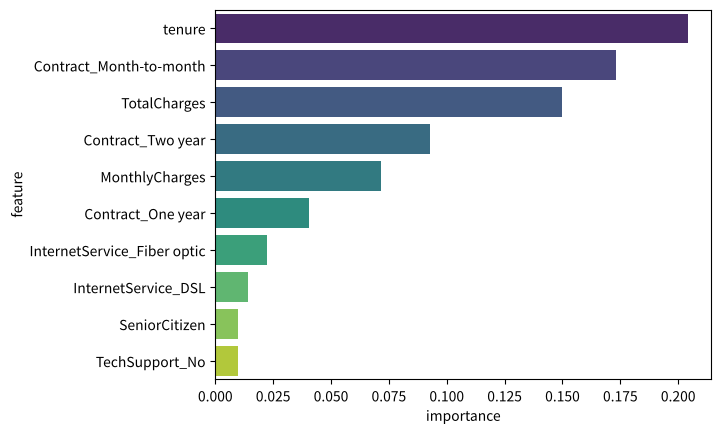

                    feature  importance
1                    tenure    0.204095
36  Contract_Month-to-month    0.173021
3              TotalCharges    0.149807


In [12]:
# [8번 정답]
# ① X_train은 스케일링 후 numpy 배열이라 columns가 없음 → X.columns
# ② GridSearchCV 객체가 아닌 best_estimator_의 feature_importances_
# ③ sort_values('importance', ascending=False)  ④ x/y 축 지정
fi = pd.DataFrame({'feature': X.columns, 'importance': gs_rf.best_estimator_.feature_importances_})
fi = fi.sort_values('importance', ascending=False)[:10]
sns.barplot(x='importance', y='feature', data=fi, palette='viridis')
plt.show()
print(fi.head(3))

답안8 = 'tenure'

<br>

### **9. F1이 가장 높은 모델의 혼동행렬을 heatmap으로 그리고 classification_report를 출력하세요.**
---
- confusion_matrix 결과를 sns.heatmap(annot=True, fmt='d')로 시각화
- 실제 이탈 고객 중 **놓친(이탈을 0으로 예측한) 고객 수**를 '답안9'에 저장하세요.
---

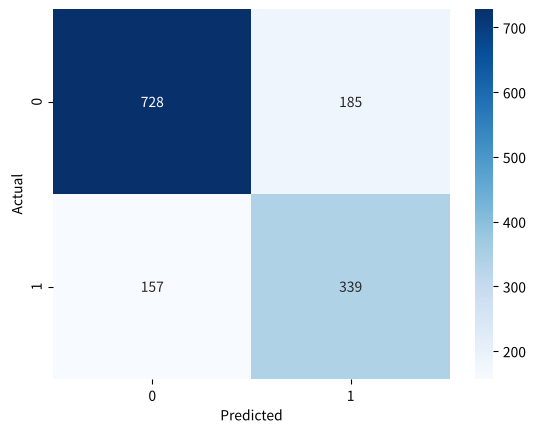

              precision    recall  f1-score   support

           0       0.82      0.80      0.81       913
           1       0.65      0.68      0.66       496

    accuracy                           0.76      1409
   macro avg       0.73      0.74      0.74      1409
weighted avg       0.76      0.76      0.76      1409



In [13]:
# [9번 정답]
cm = confusion_matrix(y_valid, y_pred_lg)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()
print(classification_report(y_valid, y_pred_lg))

답안9 = 157     # 혼동행렬 [실제 1, 예측 0] 위치 = False Negative (cm[1, 0])

<br>

## <font color=blue>**<딥러닝 모델링>**</font>

> **딥러닝 모델을 구현하기 위해 <span style="color:red">아래 코드를 실행하세요.</span>**

In [14]:
import tensorflow as tf
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Dense, Activation, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.utils import to_categorical

tf.random.set_seed(1)

### **10. 이탈 여부를 예측하는 딥러닝 모델을 만들고 학습하세요.**
---
- 토폴로지 : Dense(64, relu, 입력) → Dropout(0.3) → Dense(32, relu) → Dropout(0.3) → Dense(16, relu) → Dense(1, sigmoid)
- 모델 변수명 : model
- EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True) → estop
- ModelCheckpoint('churn_best.keras', monitor='val_loss', save_best_only=True) → mc
- optimizer='adam', loss='binary_crossentropy', metrics=['accuracy']
- epochs=100, batch_size=64, validation_data=(X_valid, y_valid), callbacks=[estop, mc]
- 학습 정보는 history에 저장하세요.
---

In [15]:
# [10번 정답]
model = Sequential([
    Dense(64, activation='relu', input_dim=X_train.shape[1]),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(16, activation='relu'),
    Dense(1, activation='sigmoid')
])

estop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
mc = ModelCheckpoint('churn_best.keras', monitor='val_loss', save_best_only=True)

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
history = model.fit(X_train, y_train, epochs=100, batch_size=64,
                    validation_data=(X_valid, y_valid), callbacks=[estop, mc], verbose=0)
print('학습 epoch 수:', len(history.history['loss']))

학습 epoch 수: 18


<br>

### **11. 학습 곡선을 그리세요.**
---
- subplots(1, 2, figsize=(14, 4))
- 왼쪽: loss / val_loss (제목 'Model Loss'), 오른쪽: accuracy / val_accuracy (제목 'Model Accuracy')
- 각 그래프의 X축은 'Epoch', 범례는 ['train', 'valid']
---

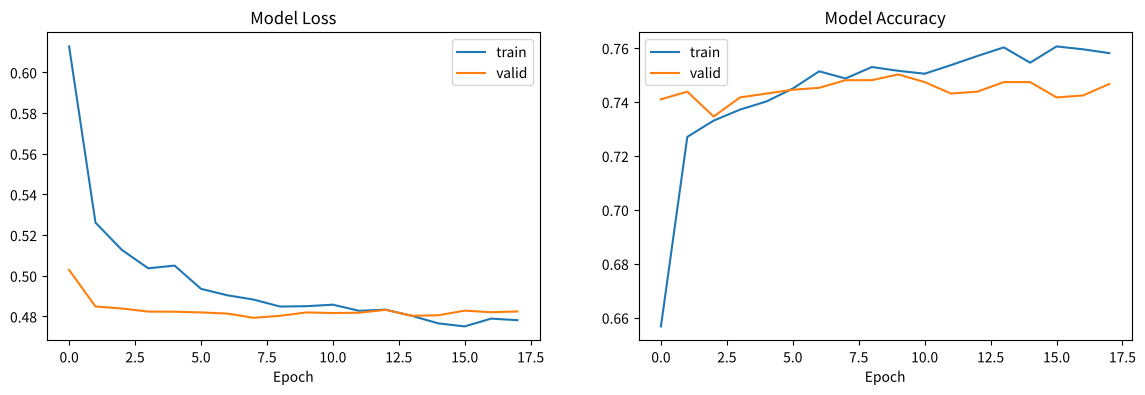

In [16]:
# [11번 정답]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(history.history['loss'])
axes[0].plot(history.history['val_loss'])
axes[0].set_title('Model Loss')
axes[0].set_xlabel('Epoch')
axes[0].legend(['train', 'valid'])

axes[1].plot(history.history['accuracy'])
axes[1].plot(history.history['val_accuracy'])
axes[1].set_title('Model Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].legend(['train', 'valid'])
plt.show()

<br>

### **12. 딥러닝 모델을 평가하고, 임계값(threshold)을 조정해 Recall을 높여 보세요.**
---
- 검증데이터의 이탈 확률을 proba에 저장하세요.
- 임계값 0.5 기준 예측값 y_pred_dl의 accuracy, recall, f1을 출력하세요.
- 임계값을 0.3으로 낮춘 예측값 y_pred_dl_03의 recall, f1을 출력하세요.
- 임계값 0.3일 때의 recall이 0.5일 때보다 **높으면 'up', 낮으면 'down'** 을 '답안12'에 저장하세요.
---

In [17]:
# [12번 정답]
proba = model.predict(X_valid, verbose=0).ravel()

y_pred_dl = (proba > 0.5).astype(int)
print('[0.5] accuracy:', accuracy_score(y_valid, y_pred_dl),
      'recall:', recall_score(y_valid, y_pred_dl), 'f1:', f1_score(y_valid, y_pred_dl))

y_pred_dl_03 = (proba > 0.3).astype(int)
print('[0.3] recall:', recall_score(y_valid, y_pred_dl_03), 'f1:', f1_score(y_valid, y_pred_dl_03))

답안12 = 'up'

[0.5] accuracy: 0.7480482611781405 recall: 0.7217741935483871 f1: 0.6685340802987861
[0.3] recall: 0.8830645161290323 f1: 0.6769706336939721


> 💡 **해설**: 임계값을 낮추면 '이탈'로 판정하는 고객이 늘어나 **Recall은 올라가고 Precision은 내려갑니다.**
> 리텐션 비용이 작고 이탈 손실이 크다면 낮은 임계값이 유리할 수 있습니다. 이런 판단이 실무 AI 모델링의 핵심입니다.

<br>

### **사례실습이 완료되었습니다. 수고하셨습니다!**